In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import functions as fn

DATA = Path("data")
OUT = Path("results"); OUT.mkdir(exist_ok=True)
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)

XLSX = DATA / "Digital_Levelling_Samdrup_Jongkhar_to_Phuntsholing.xlsx"
CSV = DATA / "Coordinates_for_BMs.csv"
BOUNDARY = None            # optional: DATA / "bhutan.geojson" or a .shp file for the outline in Fig. 1a
N_MC = 5000                # Monte Carlo realisations per scenario
SEED = 20261104            # reproduces all numbers in the paper

pd.set_option("display.precision", 2)
fn.figures.set_style()

## 1  Data
The return leg of the Changangkha spur is the exact negative of the outbound leg (a copy), so it is removed.

In [2]:
sta, extra, sec, spur_km = fn.load_data(XLSX, CSV)
n = len(sta)
A = fn.design(sec, n)                                   # station 0 (Samdrup Jongkhar BM) = datum

print(f"stations {n}, sections {len(sec)}, length {sec.L_km.sum():.1f} km (spur return leg {spur_km} km removed)")
print(f"height range {sta.Levelling_Height.min():.1f} - {sta.Levelling_Height.max():.1f} m, "
      f"cumulative |dH| = {np.abs(sec.C).sum():.0f} m")
sec.head()

stations 316, sections 315, length 822.0 km (spur return leg 2.56 km removed)
height range 169.1 - 3734.5 m, cumulative |dH| = 28977 m


,i,j,L_km,T_C,F,B,M,C,tol,tcorr
0,0,1,1.68,27.0,14.61,-14.62,14.61,14.62,0.02,2.48e-03
1,1,2,3.50,25.0,65.76,-65.76,65.76,65.77,0.02,9.86e-03
2,2,3,3.62,23.0,159.06,-159.07,159.06,159.08,0.02,2.07e-02
3,3,4,4.52,21.0,260.60,-260.61,260.61,260.64,0.03,2.87e-02
4,4,5,5.37,18.0,291.41,-291.43,291.42,291.44,0.03,2.33e-02


## 2  Noise calibration
Random error of the mean of forward and backward runs: $\delta^2 = \overline{d^2/L}/4$, $d = F + B$. All sections satisfy the 12 mm√km tolerance, so a truncated-normal estimate is also computed. The *Calibrated Mean* column is a rod-temperature correction; its coefficient is recovered by regression.

In [3]:
delta, ci, d_mm, delta_tr, tol_mm = fn.estimate_delta(sec)
alpha, T0, tres = fn.temperature_model_check(sec)
cum_corr_mm = fn.cumulative_temperature_correction(sta, sec)
sig_lev = delta * 1e-3 * np.sqrt(sec.L_km.values)        # random levelling s.d. per section (m)

calib = pd.Series({
    "delta (mm/sqrt km)": round(delta, 3),
    "95% bootstrap interval": f"{ci[0]:.2f} - {ci[1]:.2f}",
    "delta, truncated normal": round(delta_tr, 3),
    "tolerance (mm/sqrt km)": tol_mm,
    "largest misclosure / tolerance": round(float(np.max(np.abs(d_mm) / (sec.tol.values * 1e3))), 3),
    "F+B misclosure RMS / max (mm)": f"{np.sqrt(np.mean(d_mm**2)):.2f} / {np.abs(d_mm).max():.1f}",
    "temperature model": f"{alpha:.2f} ppm/degC x (T - {T0:.2f} degC), max residual {tres:.2f} ppm",
    "sum |temperature correction| (m)": round(float(np.abs(sec.tcorr).sum()), 3),
    "cumulative correction max (mm)": round(float(cum_corr_mm.max()), 1),
    "cumulative correction at Phuntsholing BM (mm)": round(float(cum_corr_mm[-1]), 1),
    "conventional s.d. at Phuntsholing BM (mm)": round(delta * np.sqrt(sec.L_km.sum()), 1),
})
calib.to_frame("value")

,value
delta (mm/sqrt km),2.52
95% bootstrap interval,2.35 - 2.70
"delta, truncated normal",2.77
tolerance (mm/sqrt km),12.0
largest misclosure / tolerance,0.98
F+B misclosure RMS / max (mm),8.59 / 29.0
temperature model,"10.00 ppm/degC x (T - 10.00 degC), max residua..."
sum |temperature correction| (m),2.66
cumulative correction max (mm),203.2
cumulative correction at Phuntsholing BM (mm),-255.1


## 3  Clock layouts
Clock comparisons are made against the reference clock at Samdrup Jongkhar BM; the reference-clock error is common to all comparisons.

In [4]:
br = fn.find_station(sta, "Changangkha Zero Order Point")
thr = int(np.argmax(sta.Levelling_Height.values))          # Thrumshingla Pass (3734 m)
towns_idx = sorted({fn.find_station(sta, t) for t in fn.TOWNS})

layouts = {"Conventional": None,
           "Case 1": np.array([0, n - 1]),
           "Case 2": np.array([0, br, n - 1]),
           "Case 3": np.array([0, thr, n - 1])}
pd.DataFrame([{"site": sta.Name_BM[k].strip(), "chainage_km": sta.chain_km[k], "height_m": sta.Levelling_Height[k]}
              for k in [0, thr, br, n - 1]])

,site,chainage_km,height_m
0,Samdrup Jongkhar BM,0.00,169.05
1,Thrumshingla Pass,361.37,3734.48
2,Changangkha Zero Order Point,667.43,2437.35
3,Phuntsholing BM,819.47,212.68


## 4  Scenario results (exact error propagation $\Sigma_x = G\Sigma G^T$)
Error models: `random`; `scale` (10 ppm rod scale); `temp` (10 % error of the temperature coefficient); `scale+temp` (reference systematic scenario); `block` (independent 10 ppm scale per 100 km). Estimators: `aware` (full covariance) and `naive` (random-model weights).

In [5]:
res, prof = fn.run_scenarios(A, sig_lev, sec, layouts)
base_rmse = res[(res.case == "Conventional") & (res.model == "random")].rmse_mm.iloc[0]

def table(model, estimator="aware"):
    d = res[(res.model == model) & (res.estimator == estimator)].copy()
    d["RMSE / worst"] = d.rmse_mm.map("{:.1f}".format) + " / " + d.worst_mm.map("{:.1f}".format)
    return d.pivot_table(index="sig_f", columns="case", values="RMSE / worst", aggfunc="first").sort_index(ascending=False)

print("Random error model (Table 2): RMSE / worst (mm)")
table("random")

Random error model (Table 2): RMSE / worst (mm)


case,Case 1,Case 2,Case 3,Conventional
sig_f,,,,
1.00e-17,47.3 / 63.1,46.2 / 62.2,46.9 / 63.1,51.5 / 72.3
3.00e-18,35.9 / 41.0,32.8 / 37.2,32.7 / 39.1,NaN
1.00e-18,30.9 / 36.7,26.4 / 33.2,23.3 / 29.2,NaN
3.00e-19,30.0 / 36.2,25.2 / 32.7,21.3 / 27.2,NaN
1.00e-19,30.0 / 36.2,25.1 / 32.6,21.1 / 27.0,NaN


In [6]:
print("Random + scale + temperature, aware estimator: RMSE / worst (mm)")
table("scale+temp")

Random + scale + temperature, aware estimator: RMSE / worst (mm)


case,Case 1,Case 2,Case 3,Conventional
sig_f,,,,
1.00e-17,53.1 / 67.3,51.1 / 65.5,51.4 / 65.7,56.6 / 76.7
3.00e-18,44.9 / 61.1,36.4 / 47.2,34.8 / 44.8,NaN
1.00e-18,41.8 / 58.9,28.6 / 39.7,24.9 / 32.7,NaN
3.00e-19,41.4 / 58.6,27.2 / 38.3,23.0 / 30.4,NaN
1.00e-19,41.3 / 58.6,27.1 / 38.1,22.8 / 30.2,NaN


In [7]:
# Table 4: all error models at sigma_f = 1e-18
rows = []
for m, e in [("random", "aware"), ("scale+temp", "aware"), ("scale+temp", "naive"), ("block", "aware")]:
    d = res[(res.model == m) & (res.estimator == e) & ((res.sig_f == 1e-18) | (res.case == "Conventional"))]
    rows.append({"model": f"{m} ({e})", **{c: f"{r.rmse_mm:.1f} / {r.worst_mm:.1f}" for c, r in zip(d.case, d.itertuples())}})
d_tr = fn.sensitivity_delta(A, sec, layouts, delta_tr)
rows.insert(1, {"model": f"random, delta = {delta_tr:.2f}", **{r.case: f"{r.rmse_mm:.1f} / {r.worst_mm:.1f}" for r in d_tr.itertuples()}})
pd.DataFrame(rows).set_index("model")

,Conventional,Case 1,Case 2,Case 3
model,,,,
random (aware),51.5 / 72.3,30.9 / 36.7,26.4 / 33.2,23.3 / 29.2
"random, delta = 2.78",56.5 / 79.4,33.7 / 40.2,28.8 / 36.4,25.3 / 31.7
scale+temp (aware),56.6 / 76.7,41.8 / 58.9,28.6 / 39.7,24.9 / 32.7
scale+temp (naive),NaN,42.3 / 60.1,30.8 / 45.5,26.9 / 37.7
block (aware),61.1 / 83.1,35.6 / 42.8,30.6 / 40.2,26.6 / 33.1


## 5  Systematic errors: profiles and sensitivity to rod-scale uncertainty

In [8]:
prof_sys = fn.systematic_profiles(A, sig_lev, sec, layouts)
sens = fn.sensitivity_scale(A, sig_lev, sec, layouts)
sens.pivot(index="sig_kappa_ppm", columns="case", values="worst_mm").round(1)

case,Case 1,Case 2,Case 3,Conventional
sig_kappa_ppm,,,,
0.0,49.4,36.3,32.6,76.7
5.0,51.9,37.4,32.6,76.7
10.0,58.9,39.7,32.7,76.7
20.0,84.5,43.6,33.2,89.7
30.0,115.9,45.6,33.5,118.7


## 6  Clock-spacing rule
$\sigma_{max}^2 \approx \delta^2 D/4 + \sigma_h^2$, checked against the full adjustment for equally spaced clocks.

In [9]:
spacing = pd.concat([fn.spacing_check(A, sig_lev, sec, sta, delta, sf) for sf in (1e-18, 1e-19)], ignore_index=True)
spacing["difference_mm"] = spacing.gls_worst_mm - spacing.rule_mm
display(spacing.round(2))

# Table 3: spacing and number of clocks for a target accuracy
L_chain = sta.chain_km.max(); rows = []
for t in (10, 15, 20, 25):
    r = {"target_mm": t}
    for sf in (1e-18, 3e-19, 1e-19):
        sh = fn.C2_G0 * sf * 1e3
        r[f"sig_f={sf:g}"] = "not reachable" if t <= sh * 1.1 else \
            f"{4*(t**2-sh**2)/delta**2:.0f} km / {int(np.ceil(L_chain/(4*(t**2-sh**2)/delta**2)))+1}"
    rows.append(r)
pd.DataFrame(rows).set_index("target_mm")

,sig_f,n_clocks,D_km,gls_worst_mm,rule_mm,difference_mm
0,0.0,2,819.47,36.72,37.29,-0.57
1,0.0,3,410.30,27.83,27.17,0.66
2,0.0,4,273.61,23.81,22.81,1.00
3,0.0,5,207.69,21.17,20.37,0.79
4,0.0,7,138.59,18.34,17.46,0.88
5,0.0,9,106.32,17.10,15.92,1.18
6,0.0,13,70.04,14.87,13.99,0.89
7,0.0,17,53.64,13.76,13.02,0.74
8,0.0,2,819.47,36.15,36.16,-0.01
9,0.0,3,410.30,25.60,25.59,0.01


,sig_f=1e-18,sig_f=3e-19,sig_f=1e-19
target_mm,,,
10,not reachable,58 km / 16,62 km / 15
15,88 km / 11,136 km / 8,141 km / 7
20,198 km / 6,246 km / 5,250 km / 5
25,339 km / 4,387 km / 4,391 km / 4


## 7  Clock siting
Third-clock scan along the line and greedy selection (σ_f = 10⁻¹⁸, random + systematic errors). This cell takes about a minute.

In [10]:
scan = {k: fn.scan_third_clock(A, sig_lev, sec, n, 1e-18, fn.scenarios.MODELS[k]) for k in ["random", "scale+temp"]}
for k in scan:
    i = int(np.nanargmin(scan[k]))
    print(f"{k:11s}: best third clock {sta.Name_BM[i].strip()} (km {sta.chain_km[i]:.0f}, {sta.Levelling_Height[i]:.0f} m), "
          f"RMSE {scan[k][i]:.1f} mm; at Changangkha {scan[k][br]:.1f} mm; at Thrumshingla {scan[k][thr]:.1f} mm")

greedy_res = {"all": fn.greedy(A, sig_lev, sec, range(1, n - 1), [0, n - 1], 1e-18, "scale+temp", 4),
              "towns": fn.greedy(A, sig_lev, sec, [t for t in towns_idx if t not in (0, n - 1)], [0, n - 1], 1e-18, "scale+temp", 4)}
greedy_tab = pd.concat([fn.greedy_table(sta, greedy_res["towns"], "candidate sites"),
                        fn.greedy_table(sta, greedy_res["all"], "any benchmark")], ignore_index=True)
greedy_tab.round(1)

random     : best third clock B?M (km 437, 2872 m), RMSE 23.0 mm; at Changangkha 26.4 mm; at Thrumshingla 23.3 mm
scale+temp : best third clock Yotongla Pass BM (km 451, 3413 m), RMSE 24.2 mm; at Changangkha 28.6 mm; at Thrumshingla 24.9 mm


,candidates,n_clocks,sites,rmse_mm,end_mm,worst_mm
0,candidate sites,2,Samdrup Jongkhar BM (km 0); Phuntsholing BM (k...,41.8,12.8,58.9
1,candidate sites,3,Samdrup Jongkhar BM (km 0); Pelela Pass BM (km...,24.8,12.8,32.0
2,candidate sites,4,Samdrup Jongkhar BM (km 0); Mongar BM (km 257)...,21.1,12.7,26.2
3,candidate sites,5,Samdrup Jongkhar BM (km 0); Mongar BM (km 257)...,19.6,12.7,25.9
4,candidate sites,6,Samdrup Jongkhar BM (km 0); Mongar BM (km 257)...,18.4,12.6,24.6
5,any benchmark,2,Samdrup Jongkhar BM (km 0); Phuntsholing BM (k...,41.8,12.8,58.9
6,any benchmark,3,Samdrup Jongkhar BM (km 0); Yotongla Pass BM (...,24.2,12.8,30.3
7,any benchmark,4,Samdrup Jongkhar BM (km 0); B?M RC42 (km 253);...,21.8,12.7,29.5
8,any benchmark,5,Samdrup Jongkhar BM (km 0); B?M RC42 (km 253);...,19.4,12.7,25.4
9,any benchmark,6,Samdrup Jongkhar BM (km 0); B?M near Bapthung ...,18.2,12.4,24.4


## 8  Monte Carlo verification
Gaussian errors, and a bootstrap of the observed misclosures for the random part.

In [11]:
verif = fn.run_verification(A, sig_lev, sec, layouts, d_mm, n_mc=N_MC, rng=np.random.default_rng(SEED))
print(f"Gaussian ratio  {verif.ratio_gauss.min():.3f} - {verif.ratio_gauss.max():.3f}")
print(f"Bootstrap ratio {verif.ratio_boot.min():.3f} - {verif.ratio_boot.max():.3f}")
verif.round(3)

Gaussian ratio  0.982 - 1.011
Bootstrap ratio 0.987 - 1.010


,case,model,sig_f,formal_rmse_mm,mc_gauss_mm,mc_boot_mm,ratio_gauss,ratio_boot
0,Conventional,random,0.0,51.46,51.41,51.72,1.00,1.00
1,Conventional,scale+temp,0.0,56.60,56.50,57.07,1.00,1.01
2,Case 1,random,0.0,47.25,46.83,47.45,0.99,1.00
3,Case 1,random,0.0,30.85,30.78,31.07,1.00,1.01
4,Case 1,random,0.0,29.96,29.87,29.76,1.00,0.99
5,Case 1,scale+temp,0.0,53.06,53.48,52.96,1.01,1.00
6,Case 1,scale+temp,0.0,41.82,41.86,41.73,1.00,1.00
7,Case 1,scale+temp,0.0,41.33,40.87,41.19,0.99,1.00
8,Case 2,random,0.0,46.21,45.67,46.36,0.99,1.00
9,Case 2,random,0.0,26.39,26.65,26.47,1.01,1.00


## 9  Save tables

In [12]:
res.to_csv(OUT / "scenario_results.csv", index=False)
verif.to_csv(OUT / "verification.csv", index=False)
greedy_tab.to_csv(OUT / "greedy_siting.csv", index=False)
sens.to_csv(OUT / "sensitivity_scale.csv", index=False)
d_tr.to_csv(OUT / "sensitivity_delta.csv", index=False)
spacing.to_csv(OUT / "spacing_rule_check.csv", index=False)
pd.DataFrame({"chain_km": sta.chain_km, "name": sta.Name_BM, "rmse_third_random": scan["random"],
              "rmse_third_sys": scan["scale+temp"]}).to_csv(OUT / "third_clock_scan.csv", index=False)
calib.to_frame("value").to_csv(OUT / "calibration_summary.csv")
sta.assign(cum_temp_corr_mm=cum_corr_mm)[["Slno", "Name_BM", "Easting", "Northing", "Levelling_Height", "chain_km",
                                          "cum_temp_corr_mm"]].to_csv(OUT / "stations.csv", index=False)
sorted(p.name for p in OUT.glob("*.csv"))

['calibration_summary.csv',
 'greedy_siting.csv',
 'scenario_results.csv',
 'sensitivity_delta.csv',
 'sensitivity_scale.csv',
 'spacing_rule_check.csv',
 'stations.csv',
 'third_clock_scan.csv',
 'verification.csv']

## 10  Figures
Each figure is saved to `results/figures/` as 600 dpi PNG and vector PDF.

In [13]:
R = dict(sta=sta, extra=extra, sec=sec, br=br, thr=thr, towns_idx=towns_idx,
         boundary=fn.read_boundary(str(BOUNDARY)) if BOUNDARY else None,
         cum_corr_mm=cum_corr_mm, prof=prof, prof_sys=prof_sys, sens=sens, res=res, base_rmse=base_rmse,
         delta=delta, delta_tr=delta_tr, tol_mm=tol_mm, d_mm=d_mm, verif=verif, scan=scan,
         greedy=greedy_res, spacing=spacing)

### Fig. 1 – Study area, height profile and cumulative temperature correction

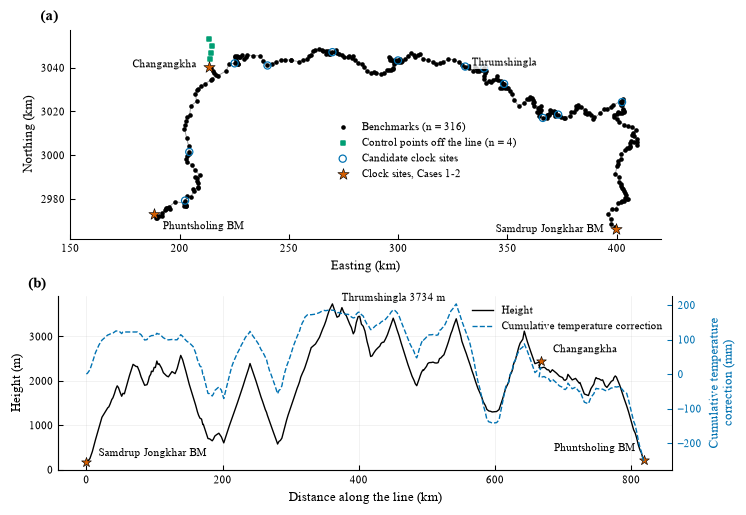

In [14]:
fig = fn.figures.fig1_study_area(R, FIG); plt.show()

### Fig. 2 – Height standard deviation along the line (random error model)

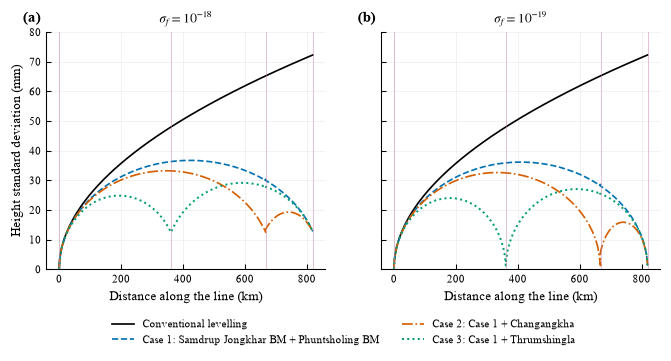

In [15]:
fig = fn.figures.fig2_error_along_line(R, FIG); plt.show()

### Fig. 3 – RMSE vs clock uncertainty; clock-spacing rule

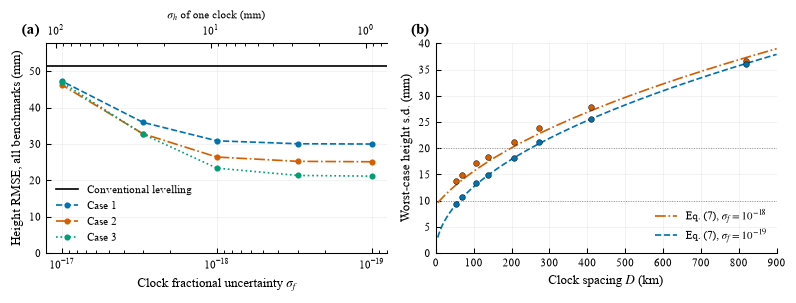

In [16]:
fig = fn.figures.fig3_clock_uncertainty_and_spacing(R, FIG); plt.show()

### Fig. 4 – Systematic errors and sensitivity to rod-scale uncertainty

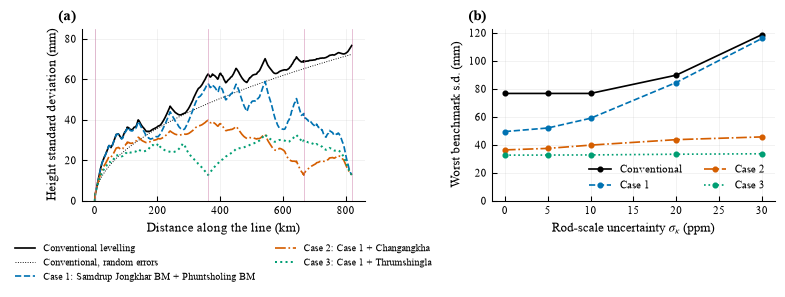

In [17]:
fig = fn.figures.fig4_systematic_errors(R, FIG); plt.show()

### Fig. 5 – Third-clock scan and greedy siting

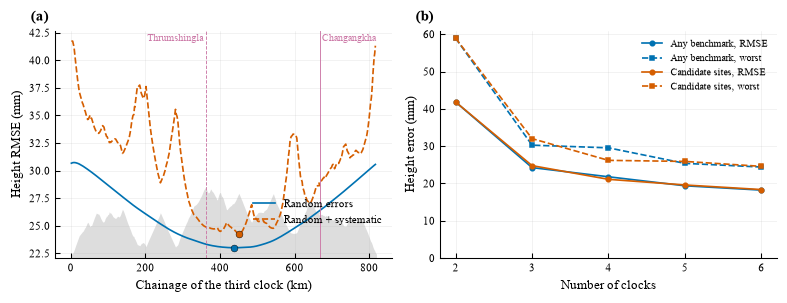

In [18]:
fig = fn.figures.fig5_clock_siting(R, FIG); plt.show()

### Fig. 6 – Misclosure distribution and Monte Carlo verification

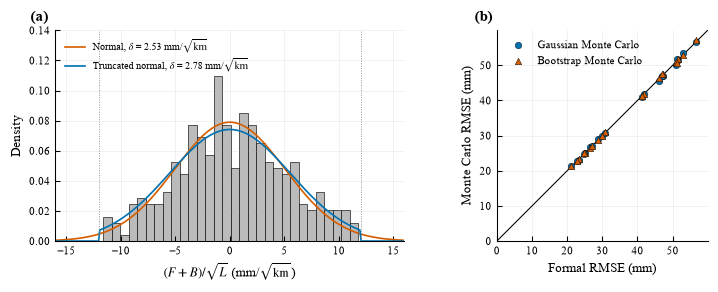

In [19]:
fig = fn.figures.fig6_model_checks(R, FIG); plt.show()

## 11  Key numbers for the manuscript

In [20]:
def row(case, model="random", sf=1e-18, est="aware"):
    d = res[(res.case == case) & (res.model == model) & (res.estimator == est)]
    if case != "Conventional": d = d[d.sig_f == sf]
    return d.iloc[0]

key = {
    "delta (mm/sqrt km)": f"{delta:.2f} ({ci[0]:.2f}-{ci[1]:.2f}); truncated {delta_tr:.2f}",
    "Conventional: RMSE / worst (mm)": f"{row('Conventional').rmse_mm:.1f} / {row('Conventional').worst_mm:.1f}",
    "Case 1, 1e-18, random: RMSE / worst": f"{row('Case 1').rmse_mm:.1f} / {row('Case 1').worst_mm:.1f}",
    "Case 3, 1e-18, random: RMSE / worst": f"{row('Case 3').rmse_mm:.1f} / {row('Case 3').worst_mm:.1f}",
    "Case 1, 1e-18, systematic: worst": f"{row('Case 1', 'scale+temp').worst_mm:.1f}",
    "Case 3, 1e-18, systematic: worst": f"{row('Case 3', 'scale+temp').worst_mm:.1f}",
    "Spacing rule max |difference| (mm)": f"{spacing.difference_mm.abs().max():.2f}",
    "1e-18 comparison = km of levelling": f"{2 * (fn.C2_G0 * 1e-18 * 1e3 / delta) ** 2:.0f}",
}
json.dump(key, open(OUT / "key_numbers.json", "w"), indent=1)
pd.Series(key).to_frame("value")

,value
delta (mm/sqrt km),2.53 (2.35-2.70); truncated 2.78
Conventional: RMSE / worst (mm),51.5 / 72.3
"Case 1, 1e-18, random: RMSE / worst",30.9 / 36.7
"Case 3, 1e-18, random: RMSE / worst",23.3 / 29.2
"Case 1, 1e-18, systematic: worst",58.9
"Case 3, 1e-18, systematic: worst",32.7
Spacing rule max |difference| (mm),1.18
1e-18 comparison = km of levelling,26
